# 02 · Modelos: ¿qué tan bien se anticipan los accidentes?

**Qué hace:**
1. Arma la **tabla celda × día**: una fila = una celda en un día, con sus variables y cuántos accidentes tuvo.
2. Separa **entrenamiento (abr 2022 – dic 2023)** y **prueba (2024)**.
3. Entrena 4 modelos y los compara: Historial, regresión de Poisson, Random Forest y XGBoost.
4. Mide qué variables pesan más y qué hace peligrosa una celda.

**Entra:** `data/celdas.csv`, `data/accidentes_celdas.csv`, `data/clima_diario.csv` (del 01)
**Sale:** `data/resultados_modelos.csv`, `data/prediccion_celdas_2024.csv`, `data/importancia.csv`, `data/rr_infraestructura.csv`, `data/resumen_modelos.csv`

~5 minutos · ~2 GB de memoria

In [1]:
import warnings
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import statsmodels.api as sm, xgboost as xgb
warnings.filterwarnings("ignore")      # avisos numéricos de statsmodels que no afectan el resultado
from sklearn.ensemble import RandomForestRegressor

plt.rcParams.update({"figure.dpi": 100, "axes.spines.top": False, "axes.spines.right": False})

# ----- Fechas -----
TRAIN_INICIO = "2022-04-01"     # ene–mar 2022 solo sirven para calcular el historial de los primeros días
TEST_INICIO = "2024-01-01"      # 2024 = prueba: ningún modelo lo ve al entrenar

# ----- Variables -----
INFRA = ["clase_via", "carriles_via", "vel_max_via", "puente", "tunel", "cruce_avenidas", "lateral", "rampas",
         "n_calles_distintas", "glorieta", "cruce_carriles_max", "n_intersecciones", "n_semaforos",
         "n_100m_comercio", "n_100m_cruce_peatonal", "n_100m_parada", "n_100m_semaforo", "n_100m_servicio",
         "dist_centro_km"]                                # 19 (se quitaron n_avenidas y semaforo: ver sección 2)
CALENDARIO = ["dow", "mes", "festivo", "semana_santa", "quincena"]
CLIMA = ["lluvia_mm", "lluvia_max_1h", "horas_lluvia", "temp_media"]
HISTORIAL = ["hist_365", "hist_90"]
VARIABLES = INFRA + CALENDARIO + CLIMA + HISTORIAL

# ----- Parámetros de los modelos -----
PARAMS_RF = dict(n_estimators=80, criterion="poisson", min_samples_leaf=200, max_features=.5,
                 max_samples=200_000, n_jobs=-1, random_state=42)
PARAMS_XGB = dict(objective="count:poisson", n_estimators=500, learning_rate=.02, max_depth=6, subsample=.8,
                  colsample_bytree=.8, min_child_weight=50, tree_method="hist", random_state=42)

## 1. La tabla celda × día
**Solo entran las celdas de buen registro** (Guadalajara, Zapopan, Tlaquepaque; ver 01, paso 5).

Así se arma:
1. **Todas las combinaciones** celda × día de 2022–2024.
2. **y = accidentes de esa celda ese día:** se agrupan los accidentes por celda y fecha y se cuentan. Si no hubo, 0.
3. Se pegan la **infraestructura** (por celda), el **calendario** y el **clima** (por día).
4. **Historial:** cuántos accidentes tuvo la celda en los 365 y en los 90 días **anteriores**, anualizados. Nunca incluye el día que se predice, para no "ver el futuro".

In [3]:
celdas = pd.read_csv("data/celdas.csv")

print(f"Celdas: {len(celdas):,} → de buen registro: {celdas.buen_registro.sum():,}")
celdas = celdas[celdas.buen_registro == 1].reset_index(drop=True)
acc = pd.read_csv("data/accidentes_celdas.csv", parse_dates=["FECHA"])
acc = acc[acc.gh7.isin(celdas.gh7)]
clima = pd.read_csv("data/clima_diario.csv", parse_dates=["FECHA"])

# 1) todas las combinaciones celda × día
fechas = pd.date_range("2022-01-01", "2024-12-31")
tabla = pd.MultiIndex.from_product([celdas.gh7, fechas], names=["gh7", "FECHA"]).to_frame(index=False)

# 2) y = accidentes por celda y día
por_celda_dia = acc.groupby(["gh7", "FECHA"]).size().rename("y").reset_index()
tabla = tabla.merge(por_celda_dia, on=["gh7", "FECHA"], how="left").fillna({"y": 0})

# 3) infraestructura, calendario y clima
FESTIVOS = pd.to_datetime(["2022-01-01", "2022-02-07", "2022-03-21", "2022-05-01", "2022-09-16", "2022-11-21", "2022-12-25",
                           "2023-01-01", "2023-02-06", "2023-03-20", "2023-05-01", "2023-09-16", "2023-11-20", "2023-12-25",
                           "2024-01-01", "2024-02-05", "2024-03-18", "2024-05-01", "2024-06-02", "2024-09-16", "2024-10-01",
                           "2024-11-18", "2024-12-25"])
SEMANA_SANTA = pd.to_datetime(["2022-04-14", "2022-04-15", "2023-04-06", "2023-04-07", "2024-03-28", "2024-03-29"])
tabla = tabla.merge(celdas[["gh7"] + INFRA], on="gh7").merge(clima, on="FECHA", how="left")
tabla["dow"], tabla["mes"] = tabla.FECHA.dt.dayofweek, tabla.FECHA.dt.month
tabla["festivo"] = tabla.FECHA.isin(FESTIVOS).astype(int)
tabla["semana_santa"] = tabla.FECHA.isin(SEMANA_SANTA).astype(int)
tabla["quincena"] = ((tabla.FECHA.dt.day == 15) | tabla.FECHA.dt.is_month_end).astype(int)

# 4) historial: promedio de los días ANTERIORES × 365 (accidentes por año)
tabla = tabla.sort_values(["gh7", "FECHA"]).reset_index(drop=True)
y_por_celda = tabla.groupby("gh7").y
tabla["hist_365"] = y_por_celda.transform(lambda s: s.shift(1).rolling(365, min_periods=1).mean() * 365)
tabla["hist_90"] = y_por_celda.transform(lambda s: s.shift(1).rolling(90, min_periods=1).mean() * 365)

tabla[VARIABLES + ["y"]] = tabla[VARIABLES + ["y"]].astype("float32")
print(f"Tabla: {len(tabla):,} filas = {len(celdas):,} celdas × {len(fechas):,} días · {tabla.memory_usage().sum() / 1e9:.1f} GB")
print(f"Accidentes: {int(tabla.y.sum()):,} · filas con accidente: {(tabla.y > 0).mean():.2%}")
tabla.sample(5, random_state=1)[["gh7", "FECHA", "clase_via", "n_intersecciones", "dow", "lluvia_mm", "hist_365", "y"]]

Celdas: 5,775 → de buen registro: 4,143
Tabla: 4,540,728 filas = 4,143 celdas × 1,096 días · 0.6 GB
Accidentes: 15,184 · filas con accidente: 0.32%


,gh7,FECHA,clase_via,n_intersecciones,dow,lluvia_mm,hist_365,y
1700018,9ewmxcz,2022-05-03,1.0,1.0,1.0,0.000000,0.0,0.0
3833656,9ewt8pu,2024-08-02,2.0,3.0,4.0,4.500000,1.0,0.0
572886,9ewmqk4,2024-02-14,1.0,5.0,2.0,2.200000,1.0,0.0
4077101,9ewt9rr,2024-12-13,1.0,2.0,4.0,0.000000,0.0,0.0
3142107,9ewt2ht,2024-08-29,2.0,6.0,3.0,25.700001,0.0,0.0


**Ojo:** solo el ~0.3% de las filas tiene un accidente. Decir siempre "no pasa nada" daría 99.7% de *accuracy* sin servir para nada. Por eso aquí no se usa accuracy, sino la **captura** (sección 4).

## 2. ¿Hay variables repetidas? (multicolinealidad)
Si dos variables dicen prácticamente lo mismo, la regresión no puede separar sus efectos. Se revisa la correlación entre todas las de infraestructura.

In [4]:
todas = INFRA + ["n_avenidas", "semaforo"]
corr = celdas[todas].corr(method="spearman")
pares = [(a, b, round(corr.loc[a, b], 2)) for i, a in enumerate(todas) for b in todas[i + 1:] if abs(corr.loc[a, b]) >= .5]
pd.DataFrame(pares, columns=["variable", "variable", "correlación"]).sort_values("correlación", ascending=False)

,variable,variable,correlación
1,cruce_avenidas,n_avenidas,0.99
6,n_100m_semaforo,semaforo,0.99
0,clase_via,vel_max_via,0.73
2,n_calles_distintas,n_intersecciones,0.67
3,n_semaforos,n_100m_semaforo,0.64
5,n_100m_comercio,n_100m_servicio,0.61
4,n_semaforos,semaforo,0.59


**Qué vemos:** `n_avenidas` ≈ `cruce_avenidas` y `semaforo` ≈ `n_100m_semaforo` (correlación 0.99): son la misma información. Por eso `n_avenidas` y `semaforo` **no están** en la lista `INFRA`. Los pares de 0.5–0.7 se dejan, pero se interpretan juntos.

## 3. Entrenamiento y prueba

In [5]:
train = tabla[(tabla.FECHA >= TRAIN_INICIO) & (tabla.FECHA < TEST_INICIO)]
test = tabla[tabla.FECHA >= TEST_INICIO]
X_train, y_train = train[VARIABLES], train.y
X_test, y_test = test[VARIABLES], test.y
print(f"Entrenamiento: {len(train):,} filas · {int(y_train.sum()):,} accidentes")
print(f"Prueba 2024:   {len(test):,} filas · {int(y_test.sum()):,} accidentes")

Entrenamiento: 2,651,520 filas · 8,397 accidentes
Prueba 2024:   1,516,338 filas · 5,636 accidentes


## 4. ¿Cómo se mide? La captura
Es pensar como quien decide dónde poner operativos:
- **Captura @10% celdas (dónde):** el modelo marca el 10% de celdas más riesgosas para 2024. ¿Qué % de los accidentes de 2024 cayó ahí?
- **Captura @1% celda-días (dónde y cuándo):** lo mismo, pero eligiendo celda y día: el 1% de todas las combinaciones del año.

In [6]:
def captura_celdas(pred, porcentaje=.10):
    por_celda = pd.DataFrame({"gh7": test.gh7.values, "pred": pred, "real": y_test.values}).groupby("gh7").sum()
    marcadas = por_celda.nlargest(int(len(por_celda) * porcentaje), "pred")
    return marcadas.real.sum() / por_celda.real.sum()

def captura_celda_dia(pred, porcentaje=.01):
    marcadas = np.argsort(-np.asarray(pred))[:int(len(pred) * porcentaje)]
    return y_test.values[marcadas].sum() / y_test.sum()

resultados, pred = {}, {}
def evaluar(nombre, p):
    pred[nombre] = np.asarray(p)
    resultados[nombre] = {"Captura @10% celdas": captura_celdas(p), "Captura @1% celda-días": captura_celda_dia(p)}
    print(f"{nombre}: dónde {resultados[nombre]['Captura @10% celdas']:.1%} · "
          f"dónde y cuándo {resultados[nombre]['Captura @1% celda-días']:.1%}")

## 5. Los modelos
### 5.1 Historial (lo que se hace hoy)
El **promedio de accidentes por día de la celda en 2022–2023**. El mismo valor para todos los días de 2024: dice dónde, pero no cuándo.

In [7]:
promedio_celda = tabla[tabla.FECHA < TEST_INICIO].groupby("gh7").y.mean()
evaluar("Historial", test.gh7.map(promedio_celda).values)

Historial: dónde 53.6% · dónde y cuándo 13.4%


### 5.2 Regresión de Poisson (el modelo interpretable)
`log(accidentes esperados) = β₀ + β₁·x₁ + β₂·x₂ + …`. Cada coeficiente, exponenciado, es una **razón de tasas**: 1.20 = +20% de accidentes.
- Necesita datos sin faltantes: velocidad → 60, carriles → 2, más un indicador de "faltaba".
- El historial entra como log, el día de la semana y el mes como categorías, y la lluvia como "día con lluvia / con lluvia fuerte".
- Por memoria se ajusta con el 25% de las filas de entrenamiento.

In [8]:
def matriz_poisson(df):
    Z = df[INFRA + ["festivo", "semana_santa", "quincena", "temp_media"]].copy()
    Z["sin_vel"] = Z.vel_max_via.isna().astype(float); Z["vel_max_via"] = Z.vel_max_via.fillna(60)
    Z["sin_carr_cruce"] = Z.cruce_carriles_max.isna().astype(float); Z["cruce_carriles_max"] = Z.cruce_carriles_max.fillna(1)
    Z["carriles_via"] = Z.carriles_via.fillna(2); Z["clase_via"] = Z.clase_via.fillna(1)
    Z["log_hist_365"] = np.log1p(df.hist_365.fillna(0))
    Z["dia_con_lluvia"] = df.lluvia_max_1h.between(.5, 5, inclusive="left").astype(float)
    Z["dia_lluvia_fuerte"] = (df.lluvia_max_1h >= 5).astype(float)
    Z = Z.join(pd.get_dummies(df.dow.astype(int), prefix="dow", drop_first=True, dtype=float))
    Z = Z.join(pd.get_dummies(df.mes.astype(int), prefix="mes", drop_first=True, dtype=float))
    return sm.add_constant(Z.fillna(0).astype(float))

muestra = train.sample(frac=.25, random_state=1)
poisson = sm.GLM(muestra.y, matriz_poisson(muestra), family=sm.families.Poisson()).fit()
evaluar("Regresión de Poisson", poisson.predict(matriz_poisson(test)))

Regresión de Poisson: dónde 57.3% · dónde y cuándo 12.9%


### 5.3 Random Forest
Muchos árboles independientes, cada uno con una muestra de los datos, cuyas predicciones se promedian. Usa el criterio Poisson (para conteos). Los parámetros están en `PARAMS_RF`, arriba.

In [9]:
relleno = {"vel_max_via": 60, "cruce_carriles_max": 1, "carriles_via": 2, "clase_via": 1}
rf = RandomForestRegressor(**PARAMS_RF).fit(X_train.fillna(relleno).fillna(0), y_train)
evaluar("Random Forest", rf.predict(X_test.fillna(relleno).fillna(0)))

Random Forest: dónde 57.6% · dónde y cuándo 14.1%


### 5.4 XGBoost
Árboles en secuencia: cada uno corrige los errores de los anteriores. Objetivo Poisson (para conteos) y maneja los faltantes solo. Los parámetros están en `PARAMS_XGB`, arriba. Los 500 árboles con tasa 0.02 se eligieron midiendo el error en octubre–diciembre 2023 (*early stopping*).

In [10]:
modelo_xgb = xgb.XGBRegressor(**PARAMS_XGB).fit(X_train, y_train)
evaluar("XGBoost", modelo_xgb.predict(X_test))

XGBoost: dónde 58.1% · dónde y cuándo 14.0%


## 6. Comparativa
**Máximo posible:** lo que capturaría alguien que supiera de antemano cuántos accidentes tendrá cada celda en 2024. Ningún modelo puede pasar de ahí.

                               Captura @10% celdas Captura @1% celda-días
Historial                                    53.6%                  13.4%
Regresión de Poisson                         57.3%                  12.9%
Random Forest                                57.6%                  14.1%
XGBoost                                      58.1%                  14.0%
Máximo posible (sabiendo 2024)               62.7%                        

XGBoost vs Historial: +4.4 puntos = ~250 accidentes más cubiertos con las mismas 414 celdas


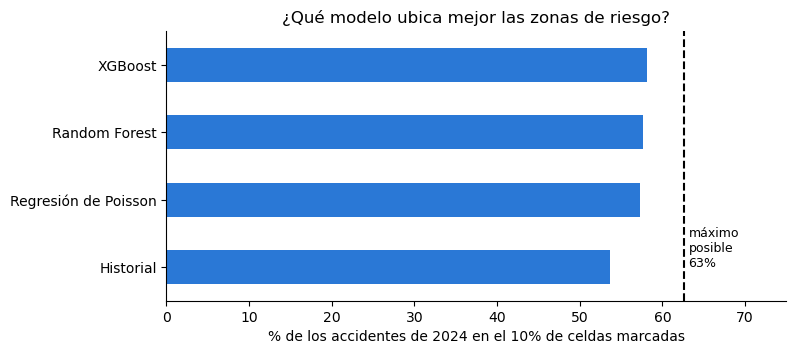

In [11]:
maximo = captura_celdas(y_test.values)
comparativa = pd.DataFrame(resultados).T
comparativa.loc["Máximo posible (sabiendo 2024)", "Captura @10% celdas"] = maximo
print(comparativa.map(lambda v: f"{v:.1%}" if pd.notna(v) else "").to_string(), "\n")

hist, mejor = comparativa.at["Historial", "Captura @10% celdas"], comparativa.at["XGBoost", "Captura @10% celdas"]
print(f"XGBoost vs Historial: {(mejor - hist) * 100:+.1f} puntos = ~{(mejor - hist) * y_test.sum():.0f} accidentes más "
      f"cubiertos con las mismas {int(len(celdas) * .10)} celdas")

orden = comparativa.drop("Máximo posible (sabiendo 2024)").sort_values("Captura @10% celdas")
ax = (orden["Captura @10% celdas"] * 100).plot(kind="barh", figsize=(8, 3.5), color="#2a78d6")
ax.axvline(maximo * 100, color="black", ls="--"); ax.text(maximo * 100 + .5, 0, f"máximo\nposible\n{maximo:.0%}", fontsize=9)
ax.set(xlabel="% de los accidentes de 2024 en el 10% de celdas marcadas", xlim=(0, 75), title="¿Qué modelo ubica mejor las zonas de riesgo?")
plt.show()

**El cambio de registro de 2024:** en 2024 se registraron más accidentes que en 2022–2023, y ningún modelo lo puede anticipar, así que todos predicen de menos en total. No afecta la captura, que solo depende del **orden** de las celdas. Para hablar de "cuántos", se multiplica la predicción por un factor (real ÷ predicho).

In [12]:
factor = y_test.sum() / pred["XGBoost"].sum()
print(f"Accidentes 2024: reales {int(y_test.sum()):,} · predichos por XGBoost {pred['XGBoost'].sum():,.0f} → factor {factor:.2f}")

Accidentes 2024: reales 5,636 · predichos por XGBoost 5,097 → factor 1.11


## 7. ¿Qué pesa más? (importancia SHAP de XGBoost)
SHAP reparte cada predicción entre las variables: cuánto subió o bajó el riesgo por cada una. Se promedia y se suma **por bloque**: ¿pesa más *dónde está la celda* (infraestructura e historial) o *qué día es* (calendario y clima)?

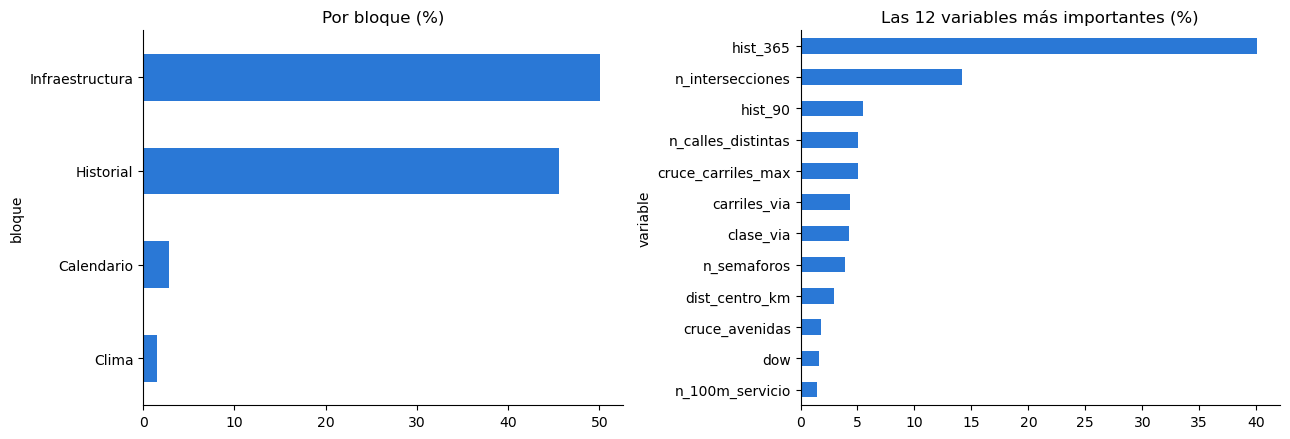

In [13]:
BLOQUE = {**{v: "Infraestructura" for v in INFRA}, **{v: "Calendario" for v in CALENDARIO},
          **{v: "Clima" for v in CLIMA}, **{v: "Historial" for v in HISTORIAL}}
muestra_test = X_test.sample(200_000, random_state=0)
shap = modelo_xgb.get_booster().predict(xgb.DMatrix(muestra_test), pred_contribs=True)[:, :-1]
importancia = pd.DataFrame({"variable": VARIABLES, "bloque": [BLOQUE[v] for v in VARIABLES],
                            "importancia": np.abs(shap).mean(axis=0)})
importancia["%"] = importancia.importancia / importancia.importancia.sum() * 100

fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
importancia.groupby("bloque")["%"].sum().sort_values().plot(kind="barh", ax=ax[0], color="#2a78d6", title="Por bloque (%)")
importancia.set_index("variable")["%"].sort_values().tail(12).plot(kind="barh", ax=ax[1], color="#2a78d6", title="Las 12 variables más importantes (%)")
plt.tight_layout(); plt.show()

## 8. ¿Qué hace peligrosa una celda? (regresión binomial negativa)
Para interpretar la infraestructura **sola**, sin historial: se cuentan los accidentes 2022–2023 de cada celda y se explican con sus variables. Es una regresión de conteos, como la de Poisson pero permitiendo que unas celdas varíen más que otras.
- El tipo de vía entra como categorías (base = secundaria).
- **RR = 1.3 → +30% de accidentes** esperados.
- `p < 0.05` = el efecto no es casualidad.

In [14]:
c = celdas.set_index("gh7")
y_celda = acc[acc.FECHA < TEST_INICIO].groupby("gh7").size().reindex(c.index, fill_value=0)
Z = c[INFRA].copy()
Z["vel_max_via"] = Z.vel_max_via.fillna(60); Z["cruce_carriles_max"] = Z.cruce_carriles_max.fillna(1)
Z["carriles_via"] = Z.carriles_via.fillna(2)
tipo = Z.pop("clase_via").fillna(1).map({1: "secundaria", 2: "primaria", 3: "troncal", 4: "autopista"})
Z = Z.join(pd.get_dummies(tipo, prefix="via", dtype=float).drop(columns="via_secundaria"))
Z["n_100m_comercio"], Z["n_100m_servicio"] = np.log1p(Z.n_100m_comercio), np.log1p(Z.n_100m_servicio)
binneg = sm.NegativeBinomial(y_celda, sm.add_constant(Z.astype(float))).fit(disp=0, maxiter=200)

NOMBRES = {"via_autopista": "Autopista / vía rápida*", "via_troncal": "Vía troncal*", "via_primaria": "Vía primaria*",
           "puente": "Puente / paso elevado", "cruce_avenidas": "Cruce de dos avenidas", "carriles_via": "Carriles de la avenida (c/u)",
           "n_intersecciones": "Intersecciones (c/u)", "cruce_carriles_max": "Carriles de la calle que cruza (c/u)",
           "dist_centro_km": "Distancia al centro (km)"}
rr = pd.DataFrame({"RR": np.exp(binneg.params), "p": binneg.pvalues}).drop(["const", "alpha"])
rr["variable"] = rr.index.map(lambda v: NOMBRES.get(v, v))
rr.sort_values("RR", ascending=False).round(3)

,RR,p,variable
via_autopista,2.146,0.000,Autopista / vía rápida*
via_troncal,2.121,0.000,Vía troncal*
puente,1.850,0.000,Puente / paso elevado
cruce_avenidas,1.501,0.000,Cruce de dos avenidas
via_primaria,1.414,0.000,Vía primaria*
n_semaforos,1.326,0.000,n_semaforos
carriles_via,1.322,0.000,Carriles de la avenida (c/u)
cruce_carriles_max,1.315,0.000,Carriles de la calle que cruza (c/u)
lateral,1.294,0.007,lateral
n_intersecciones,1.259,0.000,Intersecciones (c/u)


## 9. López Mateos: las celdas con más riesgo esperado en 2024
Es una prueba hacia atrás: el modelo solo vio 2022–2023 y se compara con lo que pasó en 2024. La predicción ya está multiplicada por el factor del cambio de registro.

In [15]:
por_celda = pd.DataFrame({"gh7": test.gh7.values, "xgb_2024": pred["XGBoost"] * factor, "real_2024": y_test.values}).groupby("gh7").sum()
salida = celdas[["gh7", "lat", "lon", "via_nombre", "es_lopez_mateos"]].join(por_celda, on="gh7")
salida["acc_2022_2023"] = salida.gh7.map(y_celda)
salida[salida.es_lopez_mateos == 1].nlargest(10, "xgb_2024")[["gh7", "via_nombre", "acc_2022_2023", "xgb_2024", "real_2024"]].round(1)

,gh7,via_nombre,acc_2022_2023,xgb_2024,real_2024
369,9ewmq2y,Anillo Periférico Poniente Manuel Gómez Morín,62,31.000000,39.0
638,9ewmqyw,Avenida Adolfo López Mateos Sur,32,24.799999,47.0
1496,9ewmx7e,Avenida Adolfo López Mateos Sur,38,22.299999,34.0
1418,9ewmx1y,Avenida Adolfo López Mateos Sur,15,14.200000,21.0
1419,9ewmx1z,Calzada Lázaro Cárdenas,9,13.600000,12.0
593,9ewmqu2,Avenida Adolfo López Mateos Sur,20,13.300000,21.0
784,9ewmrp9,Avenida Adolfo López Mateos Sur,12,11.000000,24.0
1477,9ewmx6c,Avenida Adolfo López Mateos Sur,14,10.800000,22.0
440,9ewmq9c,Avenida López Mateos Sur,10,10.600000,14.0
1412,9ewmx0u,Avenida Adolfo López Mateos Sur,19,10.500000,12.0


## 10. Guardar resultados (para el 03)

In [16]:
comparativa.to_csv("data/resultados_modelos.csv", index_label="modelo")
salida.to_csv("data/prediccion_celdas_2024.csv", index=False)
importancia.to_csv("data/importancia.csv", index=False)
rr.to_csv("data/rr_infraestructura.csv", index_label="clave")
pd.Series({"maximo": maximo, "factor": factor, "accidentes_2024": y_test.sum(), "n_celdas": len(celdas),
           "celdas_10pct": int(len(celdas) * .10)}).to_csv("data/resumen_modelos.csv", header=["valor"], index_label="clave")
print("Listo: resultados en data/")

Listo: resultados en data/
